<a href="https://colab.research.google.com/github/VictorMorais777/Disciplina-de-Inteligencia-Artificial/blob/main/Prova_Turma_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Prova Inteligência Artificial
#Turma B
---



**Nome:**João Victor da Silva de Morais

**RGM:**11241103193

**Sala:**6B

##Questões Teóricas


**1-** Por que a etapa de padronização dos atributos (StandardScaler ou MinMaxScaler) é fundamental antes de treinar um modelo SVM? O que acontece com a margem de separação se os atributos estiverem em escalas totalmente diferentes?

**R**:O svm busca a maior margem usando distancias, então atributos em escalas muito diferentes fazem o de maior escala dominar e distorcem a margem, o StandardScaler coloca todos na mesma escala.

**2-** No Kernel RBF (Radial Basis Function), qual o papel do hiperparâmetro $\gamma$? O que significa dizer que um valor de $\gamma$ é muito alto em relação ao raio de influência dos vetores de suporte?

**R**:O y controla o alcance da influencia de cada vetor de suporte, um y muito alto dá um raio de influencia pequeno, ja um y baixo da um raio de influencia grande.

**3**- Em cenários onde a detecção de falsificação ou fraude é crítica, explique por que a Acurácia isolada pode ser enganosa. Defina Precisão e Recall (Revogação) no contexto desse problema.

**R**:Em fraudes as classes são muito desbalanceadas porque fraudes são raras, então um modelo que nunca detecta fraude ainda pode ter acuracia alta, o recall é a proporção das fraudes reais que foram detectadas.

**4**- Explique o que é a técnica One-Hot Encoding e como ela pode ser aplicada para permitir sua utilização pelo modelo SVM. Apresente um exemplo de como ficaria a representação numérica de cada categoria.

**R**:One-Hot Encoding é a Tecnica de transformar uma variavel categorica em varias colunas binarias, em que apenas a coluna da categoria presente recebe o valor 1 e todas as outras 0.

##Prática
###Dataset: Student Stress Factors: A Comprehensive Analysis
https://www.kaggle.com/datasets/rxnach/student-stress-factors-a-comprehensive-analysis

import kagglehub

path = kagglehub.dataset_download("rxnach/student-stress-factors-a-comprehensive-analysis")

###Objetivo: Classificar o nível de estresse de um estudante, sendo baixo ( 0 ) moderado ( 1 ) e alto (2), utilizando SVM e logo após otimizando com GridSearch. Ao final exiba a acurácia do SVM, do GridSearch e a matriz de confusão.


In [ ]:
import kagglehub

path = kagglehub.dataset_download("rxnach/student-stress-factors-a-comprehensive-analysis")

Using Colab cache for faster access to the 'student-stress-factors-a-comprehensive-analysis' dataset.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub, os
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

In [ ]:
path = kagglehub.dataset_download("rxnach/student-stress-factors-a-comprehensive-analysis")
print(os.listdir(path))
df = pd.read_csv(os.path.join(path, "StressLevelDataset.csv"))
df.info()
df.head()
df.describe()


Using Colab cache for faster access to the 'student-stress-factors-a-comprehensive-analysis' dataset.
['StressLevelDataset.csv']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null   int64
 6   sleep_quality                 1100 non-null   int64
 7   breathing_problem             1100 non-null   int64
 8   noise_level                   1100 non-null   int64
 9   living_conditions             1100 non-null   int64
 10  safety                        1100 non-null   int64
 11  basic_needs       

,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,safety,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
count,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000
mean,11.063636,17.777273,0.492727,12.555455,2.508182,2.181818,2.660000,2.753636,2.649091,2.518182,2.737273,2.772727,2.772727,2.621818,2.648182,2.649091,1.881818,2.734545,2.767273,2.617273,0.996364
std,6.117558,8.944599,0.500175,7.727008,1.409356,0.833575,1.548383,1.400713,1.328127,1.119208,1.406171,1.433761,1.414594,1.315781,1.384579,1.529375,1.047826,1.425265,1.417562,1.530958,0.821673
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.000000,11.000000,0.000000,6.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,1.000000,2.000000,2.000000,1.000000,0.000000
50%,11.000000,19.000000,0.000000,12.000000,3.000000,2.000000,2.500000,3.000000,3.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.500000,3.000000,1.000000
75%,16.000000,26.000000,1.000000,19.000000,3.000000,3.000000,4.000000,4.000000,3.000000,3.000000,4.000000,4.000000,4.000000,3.000000,4.000000,4.000000,3.000000,4.000000,4.000000,4.000000,2.000000
max,21.000000,30.000000,1.000000,27.000000,5.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,3.000000,5.000000,5.000000,5.000000,2.000000


stress_level
0    373
2    369
1    358
Name: count, dtype: int64


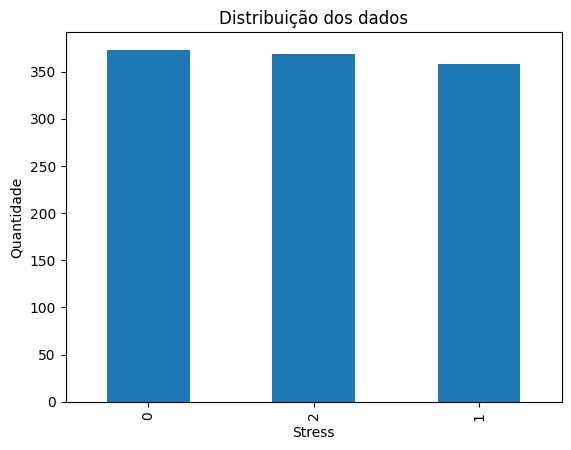

In [ ]:
print(df['stress_level'].value_counts())
df['stress_level'].value_counts().plot(kind="bar")
plt.title("Distribuição dos dados")
plt.xlabel("Stress")
plt.ylabel("Quantidade")
plt.show()

In [ ]:
X = df.drop(columns=['stress_level'])
y = df['stress_level']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
modelo = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC())
])

parametros = {
    "svc__kernel": ["linear", "rbf", "poly", "sigmoid"],
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": [0.001, 0.01, 0.1, 1]
}

grid = GridSearchCV(
    modelo,
    parametros,
    cv=5,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svc', SVC())]),
             param_grid={'svc__C': [0.1, 1, 10, 100],
                         'svc__gamma': [0.001, 0.01, 0.1, 1],
                         'svc__kernel': ['linear', 'rbf', 'poly', 'sigmoid']},
             scoring='accuracy')

In [ ]:
melhor_modelo = grid.best_estimator_
print(melhor_modelo)
print(grid.best_params_)
print(grid.best_score_)

Pipeline(steps=[('scaler', StandardScaler()),
                ('svc', SVC(C=100, gamma=0.001, kernel='linear'))])
{'svc__C': 100, 'svc__gamma': 0.001, 'svc__kernel': 'linear'}
0.8852272727272729


0.8909090909090909


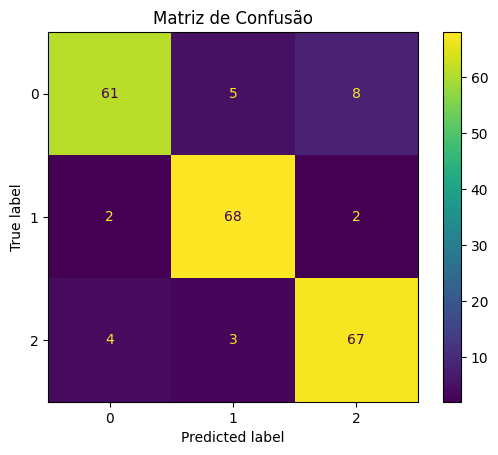

In [ ]:
y_pred = melhor_modelo.predict(X_test)
print(accuracy_score(y_test, y_pred))
classes = melhor_modelo.named_steps["svc"].classes_
matriz = confusion_matrix(y_test, y_pred, labels=classes)
ConfusionMatrixDisplay(
    confusion_matrix = matriz,
    display_labels = classes
).plot(values_format="d")
plt.title("Matriz de Confusão")
plt.show()